# Where is the headroom over EI? Basin decomposition of static arms and luck-corrected option labels

## Description

<!-- Written 2026-11-12 before the first run (pre-registration). Design: research_log/decisions/0008 (shared reasoning with Tim). Issue #13. -->

**Question.** Two rounds of candidate-level policy improvement found no advantage over EI (api_round1, api_decoder). Decision 0008 traced this to four causes:
- a linear reward;
- label noise from our own stochastic EI;
- log regret mixing basin discovery with polishing;
- one-step deviations that the horizon washes out.

Luck-corrected switching headroom does exist with task knowledge: BBOB +66% at d = 2 (decided); the prior pilot +37%, indicative only.

This experiment asks, with exact and luck-corrected labels: **is there an advantage over EI in following a different acquisition rule for k steps, and does it come from finding the right basin?** It is the signal any policy improvement needs, measured before any learning.

**Setup** (`experimental/options.py`, `tasks/option_headroom.py`). d = 2, n_init = 4, T = 20, pfn_large, fp32.
- *Deterministic arms.* Every arm maximizes its acquisition over a candidate set that depends only on the data and a seed s: a scrambled Sobol set (1024 points) plus fixed perturbations of the incumbent (64 at each of σ = 0.01, 0.05, 0.2).
  - For a fixed s, every policy is deterministic. The tasks are noise-free, so one continuation is an exact outcome.
  - Two seeds, s ∈ {0, 1}, are two equally uninformed candidate sets. They are the **luck replicates**.
  - Arms: EI, PI(ξ = 0.01), UCB(0.995), MES, posterior mean (static_tune's portfolio without ES).
- *Reward.* Terminal log10 regret, log10(best − f\* + ε) with ε = 1e-7 (BO standard).
  - f\* comes from the strong search (16384 Sobol points plus 16×200 Adam steps), lowered by every run.
  - A 16× stronger search never improved f\* by more than 1e-6 at d = 2 (track record 2026-11-12).
- *Basins (privileged, diagnostic only).*
  - Projected Adam descent on the true f (300 steps, lr 0.003) from an incumbent gives the value of the basin it drains to.
  - "Good basin" = within δ ∈ {1, 10} PFN bins (0.001) of f\*.
  - A second setting (600 steps, lr 0.001) checks the label's robustness.
- *Part A* (split 0, 500 tasks): full runs of every arm under both seeds. Per step: the regret, and whether the incumbent is in a good basin.
- *Part B* (split 4, 800 fresh tasks, task offset 20000):
  - **Branch state:** one per task, by EI (seed 0) to a step t drawn uniformly from 0–15.
  - **Base:** EI to T.
  - **Options:** each of PI, UCB, MES and mean for k ∈ {1, 3, 5} steps, then EI to T.
  - **Nulls:** `ei@j`, j ∈ {0, 1}, = EI over a fixed random half of the candidates for k steps. Same kind of deviation, no information.
  - Everything runs under both seeds; the advantage of option o under seed s is log10 R_T(base, s) − log10 R_T(o, s), positive = better.
  - Per lane, also recorded:
    - whether the first pick differs from EI's;
    - the final incumbent's basin;
    - the belief after the option: P(y(x\*) < state incumbent) and the distance from the belief's predicted minimum to x\*.

**What to look for.**
1. **Primary** (Part B): the cross-fitted headroom H₃ of the arms.
   - Per state, choose the option with the best advantage on one seed, or none if no advantage is > 0.
   - Score that choice on the other seed, average both directions, then average over states, with a bootstrap CI over states.
   - An option that is best only by luck of the candidate set does not transfer across seeds.
2. Secondary (Part B):
   - H₁ and H₅;
   - the same for the null family, and arms − nulls: the luck scale and the luck-corrected contrast;
   - the in-sample best (oracle), biased upwards, for scale;
   - per option: the mean advantage, the share that disagree with EI, the net basin gain (P(option ends in a good basin while EI does not) − the reverse), and the belief measures against the nulls at the same k;
   - everything by t.
3. Part A (descriptive):
   - P(good basin by t) per arm and seed;
   - log-regret curves per arm;
   - how much of the differences between arms is basin discovery (the regret given a good basin vs the share in a good basin);
   - seed-to-seed spread as the luck scale.

**GO / NO-GO** (rule `analysis/options.py::option_verdict`, on the arms' H₃; worthwhile = 0.022 log10, i.e. 5% less regret).
- **GO**: the CI of H₃ is above 0 and H₃ ≥ 0.022. There is a luck-corrected, exploitable advantage over EI in switching for 3 steps. Next: can the belief find it (0008 §4 step 3)?
- **NO-GO**: the upper CI bound of H₃ is < 0.022. Even with task knowledge, 3-step switching does not beat EI beyond luck on this prior at d = 2. Next: higher d, or longer options.
- **INCONCLUSIVE**: otherwise.

**Limits.**
- Noise-free P0, d = 2, T = 20 only; d = 2 is mostly solved by EI (0007).
- Two seeds make a coarse luck correction. Cross-fitting removes selection bias, but an option whose advantage depends on the candidate set itself counts as luck.
- One branch state per task.
- Basin labels by local descent can mislead (near-equal optima, valleys from irrelevant dimensions, plateaus; 0008 §3). They are a diagnostic, never the reward.
- The headroom is privileged: an upper bound on what a belief-based switching policy can reach, not a policy.


### Revision after the sanity run (2026-11-12, before the pilot)

Sanity: `results/option_headroom/sanity_20261112-110719`, 50 + 60 tasks, 3 min. The pipeline works, and the two descent settings agree on the basin label for 100% of tasks. Two changes before the pilot; the primary quantity and rule are unchanged:
1. **ε = 1e-6 instead of 1e-7.**
   - f\* is lowered by our own runs, so the lane that found the lowest value has regret exactly 0 and log10 regret = log10 ε. This affected 9% of Part A and 14% of Part B regrets.
   - With ε = 1e-7, below f\*'s accuracy of about 1e-6 (strong-search check, track record 2026-11-12), that produces artificial advantages of up to several decades.
   - Robustness at ε = 1e-5 is recomputed from the raw regrets in the analysis.
2. **A static comparator** (secondary, key for interpretation).
   - Part A suggests UCB(0.995) and MES polish better than EI on log regret. Every arm's mean advantage over EI was positive in sanity, so part of H is a *static* improvement (always switch to one arm), not a context-dependent one.
   - New rows in `headroom`:
     - `static`: the best single option, chosen by its mean advantage on one seed and scored on the other;
     - `arms-static`: the context-dependent part, H − H_static, with a paired bootstrap CI over states.
   - Reading:
     - GO with arms − static > 0 (CI) → context-dependent switching has value beyond the best static switch;
     - GO with arms − static ≈ 0 → the headroom is mostly "a better static arm than EI under log regret".

Also observed in sanity, which affects interpretation, not the design: the median τ (first step in a good basin, δ = 1 bin) is 0 for every arm. Local descent from the initial incumbent already reaches a good basin in most d = 2 tasks. So at d = 2 the differences between arms are mostly *polishing*, not basin discovery (0008 §3 anticipated this).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.options import option_verdict

SNAPSHOT = "results/option_headroom/sanity_20261112-110719"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot
cfg = snap.config["task"] if hasattr(snap, "config") else None

## How it was run

```bash
just sweep detached sanity experiment=option_headroom task.d=2 task.part_a.n_tasks=50 task.part_b.n_tasks=60 task.n_boot=200
```

|  |  |
|---|---|
| stage | sanity |
| sweep | `sanity_20261112-110719` |
| commit | `d90eda497309` (tag `sweep/option_headroom/sanity_20261112-110719`) |
| backend / host | detached / ulysses |
| ran | 2026-11-12T11:07:21 → 2026-11-12T11:10:22 |
| members | 1: 1 done |
| compute | 3.0 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/option_headroom.yaml`):

```yaml
# @package _global_
# Basin decomposition of static arms and exact, luck-corrected option labels (issue #13, decision 0008).
# Pre-registration: notebooks/12_2026-11-12_option_headroom.ipynb.
defaults:
  - override /task: option_headroom

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  deltas: '[1, 10]'
  descent.check_lr: 0.001
  descent.check_steps: 600
  descent.chunk: 65536
  descent.lr: 0.003
  descent.steps: 300
  device: cuda
  eps: 1.0e-07
  ks: '[1, 3, 5]'
  n_boot: 200
  n_init_per_d: 2
  n_null: 2
  name: option_headroom
  part_a.n_tasks: 50
  part_a.split: 0
  part_a.task_offset: 0
  part_b.n_tasks: 60
  part_b.split: 4
  part_b.t_max: 15
  part_b.task_offset: 20000
  pfn: pfn_large
  primary_k: 3
  seeds: '[0, 1]'
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tf32: false
  worthwhile_log10: 0.022
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
A, B, head, arms_b, chk = (snap.table(k) for k in ("part_a", "part_b", "headroom", "arms_b", "descent_check"))
print("Part A tasks:", A.task.nunique(), "| arms:", sorted(A.arm.unique()), "| seeds:", sorted(A.rep.unique()))
print("Part B states:", B.state.nunique(), "| options:", B.option.nunique(), "| lanes:", len(B))
print("basin label robustness (agreement of two descent settings):"); display(chk)
floor = (A.regret_bins == 0).mean(), (B.regret_bins == 0).mean()
print(f"share of regrets at the eps floor (exactly f*): Part A {floor[0]:.3f}, Part B {floor[1]:.3f}")

member status: {'DONE': 1}
minutes: {'time/part_a_s': 1.6, 'time/part_b_s': 1.4}
Part A tasks: 50 | arms: ['ei', 'mean', 'mes', 'pi0.01', 'ucb0.995'] | seeds: [np.int64(0), np.int64(1)]
Part B states: 60 | options: 19 | lanes: 2280
basin label robustness (agreement of two descent settings):


,delta_bins,agree,member
0,1.0,1.0,0
1,10.0,1.0,0


share of regrets at the eps floor (exactly f*): Part A 0.088, Part B 0.137


## 1. Part A: static arms, regret and basin discovery (split 0)

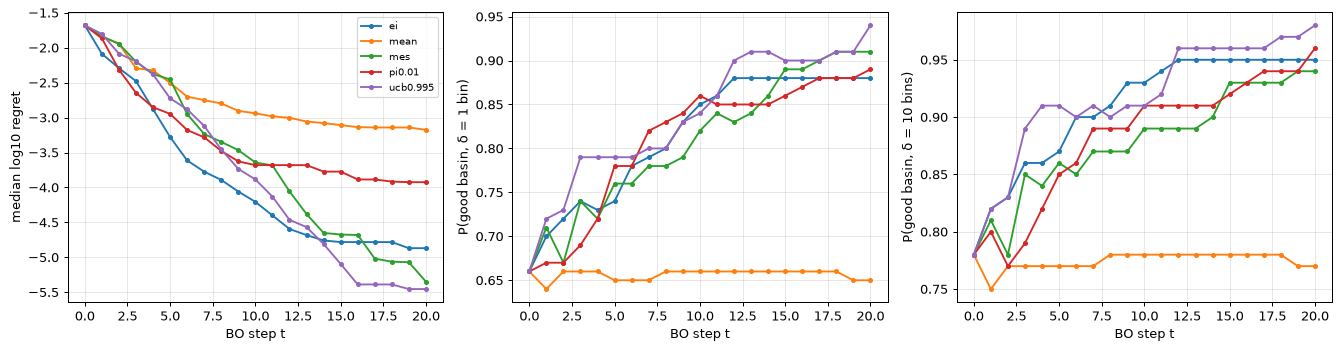

final step, per arm (both seeds pooled):


,log_regret_mean,log_regret_median,good1_T,good10_T,tau1_median,log_regret_given_good1,log_regret_given_not_good1
arm,,,,,,,
ei,-4.902,-4.869,0.88,0.95,0.0,-5.271,-2.195
mean,-3.795,-3.175,0.65,0.77,0.0,-4.957,-1.638
mes,-4.966,-5.349,0.91,0.94,0.0,-5.254,-2.057
pi0.01,-4.275,-3.925,0.89,0.96,0.0,-4.538,-2.143
ucb0.995,-5.079,-5.454,0.94,0.98,0.0,-5.251,-2.388


seed-to-seed |Δ log10 regret| (luck scale), median / mean by arm:


,median,mean
arm,,
ei,0.295,0.420
mean,0.053,0.566
mes,0.072,0.359
pi0.01,0.509,0.825
ucb0.995,0.270,0.425


In [ ]:
T = A.t.max()
for dl in (1, 10):
    A[f"good{dl}"] = A.basin_gap_bins <= dl
fig, ax = plt.subplots(1, 3, figsize=(15, 4), dpi=90)
for arm, g in A.groupby("arm"):
    m = g.groupby("t").log_regret.median()
    ax[0].plot(m.index, m, marker=".", label=arm)
    ax[1].plot(g.groupby("t").good1.mean(), marker=".", label=arm)
    ax[2].plot(g.groupby("t").good10.mean(), marker=".", label=arm)
ax[0].set_ylabel("median log10 regret"); ax[1].set_ylabel("P(good basin, δ = 1 bin)"); ax[2].set_ylabel("P(good basin, δ = 10 bins)")
for x in ax: x.set_xlabel("BO step t"); x.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
fin = A[A.t == T]
tau = A[A.good1].groupby(["task", "arm", "rep"]).t.min()
summ = fin.groupby("arm").agg(log_regret_mean=("log_regret", "mean"), log_regret_median=("log_regret", "median"),
                              good1_T=("good1", "mean"), good10_T=("good10", "mean"))
summ["tau1_median"] = tau.groupby("arm").median()
summ["log_regret_given_good1"] = fin[fin.good1].groupby("arm").log_regret.mean()
summ["log_regret_given_not_good1"] = fin[~fin.good1].groupby("arm").log_regret.mean()
print("final step, per arm (both seeds pooled):"); display(summ.round(3))
sp = fin.pivot_table(index=["task", "arm"], columns="rep", values="log_regret")
print("seed-to-seed |Δ log10 regret| (luck scale), median / mean by arm:")
display((sp[0] - sp[1]).abs().groupby("arm").agg(["median", "mean"]).round(3))

## 2. Part B: luck-corrected option headroom (split 4)

H = cross-fitted headroom (choose the best option on one seed, score it on the other), in log10 regret; positive = better than EI. Oracle = in-sample best (biased upwards). The null family (EI on a random half of the candidates) is the luck scale.

In [ ]:
display(head.round(4))
cols = ["option", "adv_mean", "lo", "hi", "adv_median", "share_pos", "share_neg", "disagree",
        "basin_gain_1", "basin_gain_10", "pi_xstar", "dist_argmin_xstar"]
display(arms_b[cols].sort_values(["option"]).round(4))

,k,family,H,lo,hi,oracle,oracle_lo,oracle_hi,deviates,n_states,member
0,1,arms,0.1922,0.0735,0.3364,0.3965,0.2367,0.6366,0.4667,60.0,0
1,1,nulls,-0.0231,-0.0796,0.0092,0.0707,0.0165,0.1494,0.1667,60.0,0
2,1,arms-nulls,0.2153,0.0721,0.3843,NaN,NaN,NaN,NaN,NaN,0
3,3,arms,0.2826,0.1221,0.5094,0.5844,0.3397,0.8212,0.5667,60.0,0
4,3,nulls,-0.0744,-0.1298,-0.0231,0.1286,0.0629,0.2075,0.2667,60.0,0
5,3,arms-nulls,0.3570,0.1966,0.5964,NaN,NaN,NaN,NaN,NaN,0
6,5,arms,0.5106,0.2311,0.7994,0.7811,0.5060,1.0510,0.5667,60.0,0
7,5,nulls,-0.0608,-0.1162,-0.0082,0.2009,0.0973,0.3193,0.3000,60.0,0
8,5,arms-nulls,0.5714,0.3092,0.8606,NaN,NaN,NaN,NaN,NaN,0


,option,adv_mean,lo,hi,adv_median,share_pos,share_neg,disagree,basin_gain_1,basin_gain_10,pi_xstar,dist_argmin_xstar
0,mean_k1,0.0216,-0.0745,0.1291,0.0,0.2083,0.1833,0.7583,-0.0083,-0.0083,0.3577,0.2544
1,mean_k3,0.1509,0.0300,0.3096,0.0,0.3500,0.2250,0.7583,0.0000,-0.0167,0.3799,0.2768
2,mean_k5,0.1008,-0.0600,0.2768,0.0,0.3417,0.2750,0.7583,0.0083,0.0000,0.4039,0.2677
3,mes_k1,0.1306,0.0237,0.2302,0.0,0.2583,0.1333,0.8167,0.0167,0.0333,0.3752,0.3046
4,mes_k3,0.0857,-0.0564,0.2318,0.0,0.3083,0.2667,0.8167,-0.0083,0.0000,0.4108,0.2756
5,mes_k5,0.1803,0.0082,0.3428,0.0,0.3167,0.2667,0.8167,0.0167,0.0083,0.4707,0.2795
6,null0_k1,-0.0031,-0.0997,0.0801,0.0,0.0667,0.1083,0.5000,0.0000,0.0000,0.3740,0.2617
7,null0_k3,0.0051,-0.0884,0.0998,0.0,0.1750,0.1667,0.5000,-0.0083,-0.0083,0.4236,0.2520
8,null0_k5,0.0352,-0.0898,0.1372,0.0,0.1833,0.2250,0.5000,-0.0167,-0.0167,0.4640,0.2316
9,null1_k1,0.0092,-0.0043,0.0273,0.0,0.1167,0.0750,0.4583,0.0000,0.0000,0.3749,0.2622


mean advantage by branch step and k (arms vs nulls):


family      arms                   nulls                
k              1       3       5       1       3       5
t_bin                                                   
(-1, 3]   0.1864  0.2370  0.1408 -0.0230 -0.0836  0.0424
(3, 7]    0.1831  0.1135  0.2560  0.0050 -0.0767  0.0114
(7, 11]   0.0412  0.1180  0.2191  0.0174  0.0216  0.0765
(11, 15]  0.0272  0.0613  0.1500  0.0045  0.0063 -0.0070

share of lanes whose advantage is exactly 0:


family,arms,nulls
k,,
1,0.588,0.817
3,0.412,0.646
5,0.400,0.575


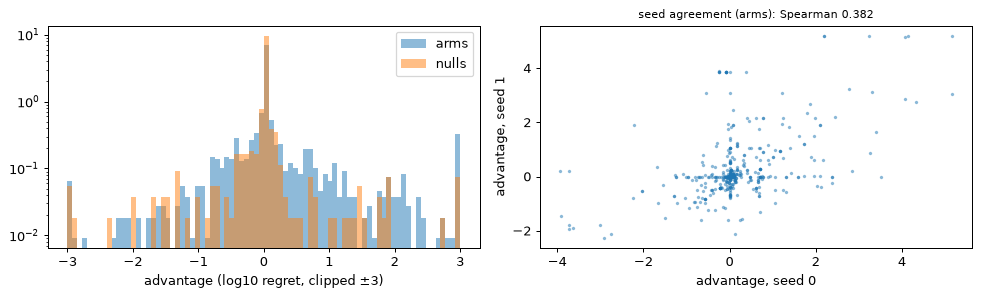

In [ ]:
B["t_bin"] = pd.cut(B.t, [-1, 3, 7, 11, 15])
nb = B[B.option != "base"].copy()
nb["family"] = np.where(nb.arm.str.startswith("ei@"), "nulls", "arms")
print("mean advantage by branch step and k (arms vs nulls):")
display(nb.pivot_table(index="t_bin", columns=["family", "k"], values="adv", aggfunc="mean", observed=True).round(4))
print("share of lanes whose advantage is exactly 0:")
display(nb.assign(zero=nb.adv.abs() < 1e-12).pivot_table(index="k", columns="family", values="zero", aggfunc="mean").round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
for f, g in nb.groupby("family"):
    ax[0].hist(np.clip(g.adv, -3, 3), bins=80, alpha=.5, label=f, density=True)
ax[0].set_yscale("log"); ax[0].set_xlabel("advantage (log10 regret, clipped ±3)"); ax[0].legend()
a = nb[nb.family == "arms"].pivot_table(index=["state", "option"], columns="rep", values="adv")
ax[1].scatter(a[0], a[1], s=3, alpha=.4); ax[1].set_xlabel("advantage, seed 0"); ax[1].set_ylabel("advantage, seed 1")
ax[1].set_title(f"seed agreement (arms): Spearman {a[0].corr(a[1], method='spearman'):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

## Verdict

In [ ]:
k = 3
print("verdict (analysis/options.py::option_verdict, arms' H at k = 3):", option_verdict(head, k, 0.022))

verdict (analysis/options.py::option_verdict, arms' H at k = 3): GO
